# Analisis Regresi Linier Berganda
## I Ketut Tangkas Agus Sucita (2308561022)

---

Mata Kuliah  : Intelijen Bisnis dan Analisis
Jenis Tugas  : Tugas Individu
Metode       : Multiple Linear Regression (OLS)
Dataset      : Salary_Data — Kaggle
Link         : https://www.kaggle.com/datasets/mohithsairamreddy/salary-data

---

Variabel Penelitian:

    X1 — Usia               : Usia karyawan (tahun) — Independen
    X2 — Jenis Kelamin      : Jenis kelamin karyawan — Independen
    X3 — Tingkat Pendidikan : SMA / S1 / S2 / S3 — Independen
    X4 — Jabatan            : Posisi / jabatan karyawan — Independen
    X5 — Tahun Pengalaman   : Lama pengalaman kerja (tahun) — Independen
    Y  — Gaji               : Gaji karyawan (USD) — Dependen

---
## Bagian 1 — Instalasi dan Import Library

In [31]:
!pip install statsmodels --quiet

print("Instalasi selesai.")

Instalasi selesai.


In [32]:
import io
import warnings

import numpy             as np
import pandas            as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn           as sns

from sklearn.linear_model    import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing   import LabelEncoder
from sklearn.metrics         import r2_score, mean_squared_error, mean_absolute_error
import statsmodels.api       as sm

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.4f}".format)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})

print("Semua library berhasil diimpor.")
print(f"  pandas       : {pd.__version__}")
print(f"  numpy        : {np.__version__}")
print(f"  scikit-learn : {__import__('sklearn').__version__}")
print(f"  statsmodels  : {__import__('statsmodels').__version__}")

Semua library berhasil diimpor.
  pandas       : 2.2.2
  numpy        : 2.0.2
  scikit-learn : 1.6.1
  statsmodels  : 0.14.6


---
## Bagian 2 — Upload Dataset

Dataset yang digunakan adalah Salary_Data dari Kaggle.  

> Sumber: [https://www.kaggle.com/datasets/mohithsairamreddy/salary-data](https://www.kaggle.com/datasets/mohithsairamreddy/salary-data)

In [3]:
from google.colab import files

print("Silakan pilih file Salary_Data.csv dari komputer Anda ...")
uploaded = files.upload()

nama_file = list(uploaded.keys())[0]
print(f"File '{nama_file}' berhasil diupload.")

Silakan pilih file Salary_Data.csv dari komputer Anda ...


Saving Salary_Data.csv to Salary_Data.csv
File 'Salary_Data.csv' berhasil diupload.


---
## Bagian 3 — Pemahaman Dataset

Tahap ini bertujuan untuk memahami struktur dataset sebelum dilakukan analisis lebih lanjut,
meliputi jumlah data, nama kolom, tipe data, dan gambaran umum statistik deskriptif.

In [4]:
df_raw = pd.read_csv(io.BytesIO(uploaded[nama_file]))

print("=" * 55)
print("  INFO DATASET")
print("=" * 55)
print(f"  File         : {nama_file}")
print(f"  Jumlah baris : {df_raw.shape[0]:,}")
print(f"  Jumlah kolom : {df_raw.shape[1]}")
print("")
print("  Kolom yang tersedia:")
for i, col in enumerate(df_raw.columns, 1):
    print(f"    {i}. {col:<25} (dtype: {df_raw[col].dtype})")

  INFO DATASET
  File         : Salary_Data.csv
  Jumlah baris : 6,704
  Jumlah kolom : 6

  Kolom yang tersedia:
    1. Age                       (dtype: float64)
    2. Gender                    (dtype: object)
    3. Education Level           (dtype: object)
    4. Job Title                 (dtype: object)
    5. Years of Experience       (dtype: float64)
    6. Salary                    (dtype: float64)


In [5]:
df = df_raw.copy()
df.columns = [
    "Usia", "Jenis_Kelamin", "Tingkat_Pendidikan",
    "Jabatan", "Tahun_Pengalaman", "Gaji"
]

print("Nama kolom berhasil diubah ke Bahasa Indonesia:")
print("")
for asli, baru in zip(df_raw.columns, df.columns):
    print(f"  {asli:<25} ->  {baru}")

Nama kolom berhasil diubah ke Bahasa Indonesia:

  Age                       ->  Usia
  Gender                    ->  Jenis_Kelamin
  Education Level           ->  Tingkat_Pendidikan
  Job Title                 ->  Jabatan
  Years of Experience       ->  Tahun_Pengalaman
  Salary                    ->  Gaji


In [6]:
print("Sepuluh baris pertama dataset:")
df.head(10)

Sepuluh baris pertama dataset:


,Usia,Jenis_Kelamin,Tingkat_Pendidikan,Jabatan,Tahun_Pengalaman,Gaji
0,32.0000,Male,Bachelor's,Software Engineer,5.0000,"90,000.0000"
1,28.0000,Female,Master's,Data Analyst,3.0000,"65,000.0000"
2,45.0000,Male,PhD,Senior Manager,15.0000,"150,000.0000"
3,36.0000,Female,Bachelor's,Sales Associate,7.0000,"60,000.0000"
4,52.0000,Male,Master's,Director,20.0000,"200,000.0000"
5,29.0000,Male,Bachelor's,Marketing Analyst,2.0000,"55,000.0000"
6,42.0000,Female,Master's,Product Manager,12.0000,"120,000.0000"
7,31.0000,Male,Bachelor's,Sales Manager,4.0000,"80,000.0000"
8,26.0000,Female,Bachelor's,Marketing Coordinator,1.0000,"45,000.0000"
9,38.0000,Male,PhD,Senior Scientist,10.0000,"110,000.0000"


In [7]:
print("Informasi tipe data:")
df.info()

Informasi tipe data:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6704 entries, 0 to 6703
Data columns (total 6 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Usia                6702 non-null   float64
 1   Jenis_Kelamin       6702 non-null   object 
 2   Tingkat_Pendidikan  6701 non-null   object 
 3   Jabatan             6702 non-null   object 
 4   Tahun_Pengalaman    6701 non-null   float64
 5   Gaji                6699 non-null   float64
dtypes: float64(3), object(3)
memory usage: 314.4+ KB


In [8]:
print("Statistik deskriptif dataset:")
df.describe(include="all").round(2)

Statistik deskriptif dataset:


,Usia,Jenis_Kelamin,Tingkat_Pendidikan,Jabatan,Tahun_Pengalaman,Gaji
count,"6,702.0000",6702,6701,6702,"6,701.0000","6,699.0000"
unique,NaN,3,7,193,NaN,NaN
top,NaN,Male,Bachelor's Degree,Software Engineer,NaN,NaN
freq,NaN,3674,2267,518,NaN,NaN
mean,33.6200,NaN,NaN,NaN,8.0900,"115,326.9600"
std,7.6100,NaN,NaN,NaN,6.0600,"52,786.1800"
min,21.0000,NaN,NaN,NaN,0.0000,350.0000
25%,28.0000,NaN,NaN,NaN,3.0000,"70,000.0000"
50%,32.0000,NaN,NaN,NaN,7.0000,"115,000.0000"
75%,38.0000,NaN,NaN,NaN,12.0000,"160,000.0000"


---
## Bagian 4 — Data Preparation

Tahap persiapan data sebelum pemodelan, meliputi :
1. Pemeriksaan dan penanganan missing values
2. Standarisasi nilai pada kolom Tingkat Pendidikan yang tidak konsisten
3. Label Encoding untuk mengubah variabel kategorik menjadi numerik

In [9]:
print("=" * 50)
print("  CEK MISSING VALUES")
print("=" * 50)

mv     = df.isnull().sum()
mv_pct = (mv / len(df) * 100).round(2)
mv_tbl = pd.DataFrame({"Jumlah Missing": mv, "Persentase (%)": mv_pct})
print(mv_tbl)
print(f"")
print(f"  Total missing : {mv.sum()} dari {len(df):,} baris")

  CEK MISSING VALUES
                    Jumlah Missing  Persentase (%)
Usia                             2          0.0300
Jenis_Kelamin                    2          0.0300
Tingkat_Pendidikan               3          0.0400
Jabatan                          2          0.0300
Tahun_Pengalaman                 3          0.0400
Gaji                             5          0.0700

  Total missing : 17 dari 6,704 baris


In [10]:
print("Nilai unik Tingkat_Pendidikan SEBELUM standarisasi:")
print(df["Tingkat_Pendidikan"].value_counts(dropna=False))

edu_map = {
    "Bachelor's"        : "S1",
    "Bachelor's Degree" : "S1",
    "Master's"          : "S2",
    "Master's Degree"   : "S2",
    "PhD"               : "S3",
    "phD"               : "S3",
    "High School"       : "SMA",
}
df["Tingkat_Pendidikan"] = df["Tingkat_Pendidikan"].map(edu_map)

print("")
print("Nilai unik Tingkat_Pendidikan SETELAH standarisasi:")
print(df["Tingkat_Pendidikan"].value_counts(dropna=False))

Nilai unik Tingkat_Pendidikan SEBELUM standarisasi:
Tingkat_Pendidikan
Bachelor's Degree    2267
Master's Degree      1573
PhD                  1368
Bachelor's            756
High School           448
Master's              288
NaN                     3
phD                     1
Name: count, dtype: int64

Nilai unik Tingkat_Pendidikan SETELAH standarisasi:
Tingkat_Pendidikan
S1     3023
S2     1861
S3     1369
SMA     448
NaN       3
Name: count, dtype: int64


In [11]:
sebelum = len(df)
df.dropna(inplace=True)
df.reset_index(drop=True, inplace=True)
sesudah = len(df)

print(f"  Baris sebelum cleaning : {sebelum:,}")
print(f"  Baris sesudah cleaning : {sesudah:,}")
print(f"  Baris dihapus          : {sebelum - sesudah:,} ({(sebelum - sesudah) / sebelum * 100:.2f}%)")
print("")
print("Missing values berhasil ditangani.")

  Baris sebelum cleaning : 6,704
  Baris sesudah cleaning : 6,698
  Baris dihapus          : 6 (0.09%)

Missing values berhasil ditangani.


In [12]:
le_gender = LabelEncoder()
le_edu    = LabelEncoder()
le_job    = LabelEncoder()

df["Jenis_Kelamin_Enc"]      = le_gender.fit_transform(df["Jenis_Kelamin"])
df["Tingkat_Pendidikan_Enc"] = le_edu.fit_transform(df["Tingkat_Pendidikan"])
df["Jabatan_Enc"]            = le_job.fit_transform(df["Jabatan"])

print("=== HASIL LABEL ENCODING ===")
print("")
print("Jenis Kelamin:")
for kls, val in zip(le_gender.classes_, le_gender.transform(le_gender.classes_)):
    print(f"   {kls:<10} -> {val}")

print("")
print("Tingkat Pendidikan:")
for kls, val in zip(le_edu.classes_, le_edu.transform(le_edu.classes_)):
    print(f"   {kls:<10} -> {val}")

print("")
print(f"Jabatan: {df['Jabatan'].nunique()} jabatan unik -> angka 0 s.d. {df['Jabatan'].nunique() - 1}")

print("")
print("Cuplikan hasil encoding (5 baris pertama):")
df[["Usia", "Jenis_Kelamin", "Jenis_Kelamin_Enc",
    "Tingkat_Pendidikan", "Tingkat_Pendidikan_Enc",
    "Jabatan", "Jabatan_Enc", "Tahun_Pengalaman", "Gaji"]].head(5)

=== HASIL LABEL ENCODING ===

Jenis Kelamin:
   Female     -> 0
   Male       -> 1
   Other      -> 2

Tingkat Pendidikan:
   S1         -> 0
   S2         -> 1
   S3         -> 2
   SMA        -> 3

Jabatan: 191 jabatan unik -> angka 0 s.d. 190

Cuplikan hasil encoding (5 baris pertama):


,Usia,Jenis_Kelamin,Jenis_Kelamin_Enc,Tingkat_Pendidikan,Tingkat_Pendidikan_Enc,Jabatan,Jabatan_Enc,Tahun_Pengalaman,Gaji
0,32.0000,Male,1,S1,0,Software Engineer,175,5.0000,"90,000.0000"
1,28.0000,Female,0,S2,1,Data Analyst,18,3.0000,"65,000.0000"
2,45.0000,Male,1,S3,2,Senior Manager,144,15.0000,"150,000.0000"
3,36.0000,Female,0,S1,0,Sales Associate,115,7.0000,"60,000.0000"
4,52.0000,Male,1,S2,1,Director,25,20.0000,"200,000.0000"


In [13]:
print(f"Dataset siap dianalisis: {df.shape[0]:,} baris x {df.shape[1]} kolom")
df[["Usia", "Jenis_Kelamin_Enc", "Tingkat_Pendidikan_Enc",
    "Jabatan_Enc", "Tahun_Pengalaman", "Gaji"]].describe().round(2)

Dataset siap dianalisis: 6,698 baris x 9 kolom


,Usia,Jenis_Kelamin_Enc,Tingkat_Pendidikan_Enc,Jabatan_Enc,Tahun_Pengalaman,Gaji
count,"6,698.0000","6,698.0000","6,698.0000","6,698.0000","6,698.0000","6,698.0000"
mean,33.6200,0.5500,0.8900,94.1400,8.1000,"115,329.2500"
std,7.6200,0.5000,0.9500,58.4500,6.0600,"52,789.7900"
min,21.0000,0.0000,0.0000,0.0000,0.0000,350.0000
25%,28.0000,0.0000,0.0000,42.2500,3.0000,"70,000.0000"
50%,32.0000,1.0000,1.0000,96.0000,7.0000,"115,000.0000"
75%,38.0000,1.0000,2.0000,158.0000,12.0000,"160,000.0000"
max,62.0000,2.0000,3.0000,190.0000,34.0000,"250,000.0000"


---
## Bagian 5 — Analisis Hubungan Antar Variabel

Eksplorasi korelasi dan distribusi data melalui statistik deskriptif dan visualisasi
sebelum membangun model regresi.

Panduan kekuatan korelasi Pearson (r):
    0.80 - 1.00  :  Sangat Kuat
    0.60 - 0.79  :  Kuat
    0.40 - 0.59  :  Sedang
    0.20 - 0.39  :  Lemah
    0.00 - 0.19  :  Sangat Lemah

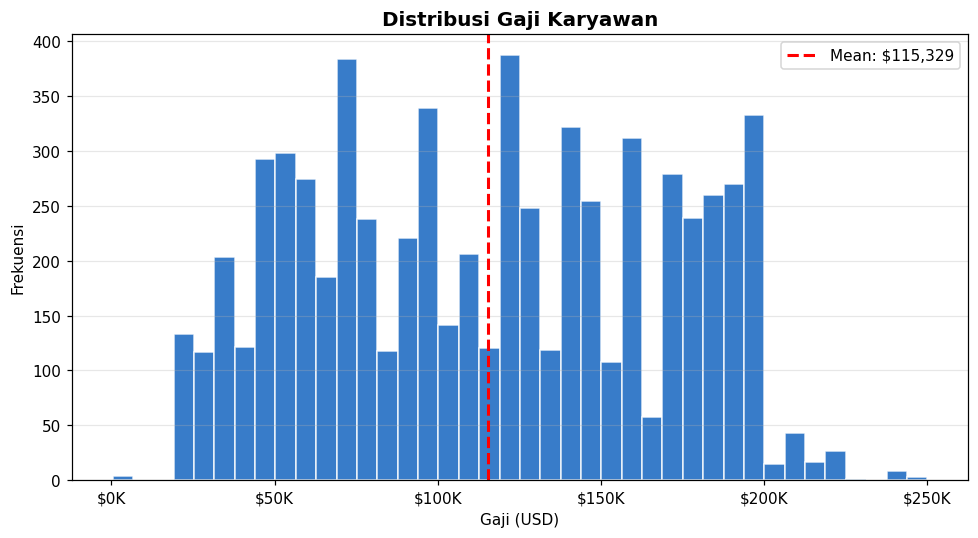

  Rata-rata Gaji : $115,329.25
  Median Gaji    : $115,000.00
  Std Dev        : $52,789.79


In [14]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.hist(df["Gaji"], bins=40, color="#1565C0", edgecolor="white", alpha=0.85)
ax.set_title("Distribusi Gaji Karyawan", fontsize=13, fontweight="bold")
ax.set_xlabel("Gaji (USD)")
ax.set_ylabel("Frekuensi")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"${x/1000:.0f}K"))
mean_gaji = df["Gaji"].mean()
ax.axvline(mean_gaji, color="red", linestyle="--", linewidth=2,
           label=f"Mean: ${mean_gaji:,.0f}")
ax.legend()
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print(f"  Rata-rata Gaji : ${mean_gaji:,.2f}")
print(f"  Median Gaji    : ${df['Gaji'].median():,.2f}")
print(f"  Std Dev        : ${df['Gaji'].std():,.2f}")

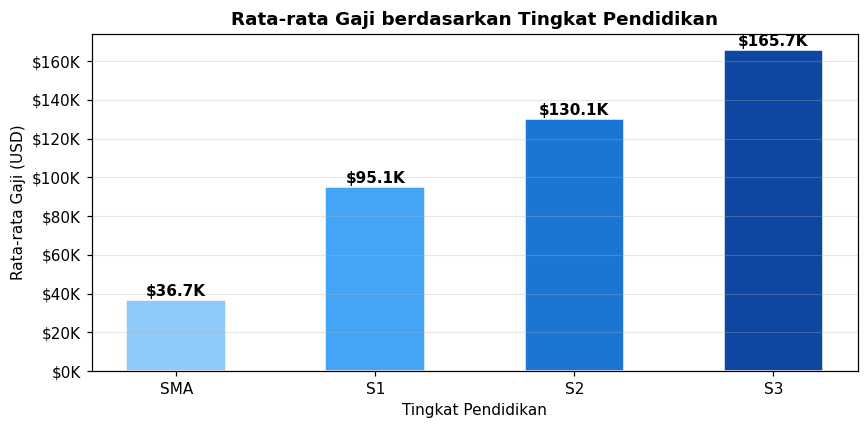

In [15]:
fig, ax = plt.subplots(figsize=(8, 4))
urutan   = ["SMA", "S1", "S2", "S3"]
gaji_edu = (df.groupby("Tingkat_Pendidikan")["Gaji"]
              .mean()
              .reindex(urutan)
              .dropna())

warna = ["#90CAF9", "#42A5F5", "#1976D2", "#0D47A1"][:len(gaji_edu)]
bars  = ax.bar(gaji_edu.index, gaji_edu.values, color=warna,
               edgecolor="white", width=0.5)
ax.set_title("Rata-rata Gaji berdasarkan Tingkat Pendidikan",
             fontsize=12, fontweight="bold")
ax.set_xlabel("Tingkat Pendidikan")
ax.set_ylabel("Rata-rata Gaji (USD)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"${x/1000:.0f}K"))
for bar, val in zip(bars, gaji_edu.values):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 500,
            f"${val/1000:.1f}K", ha="center", va="bottom",
            fontsize=10, fontweight="bold")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

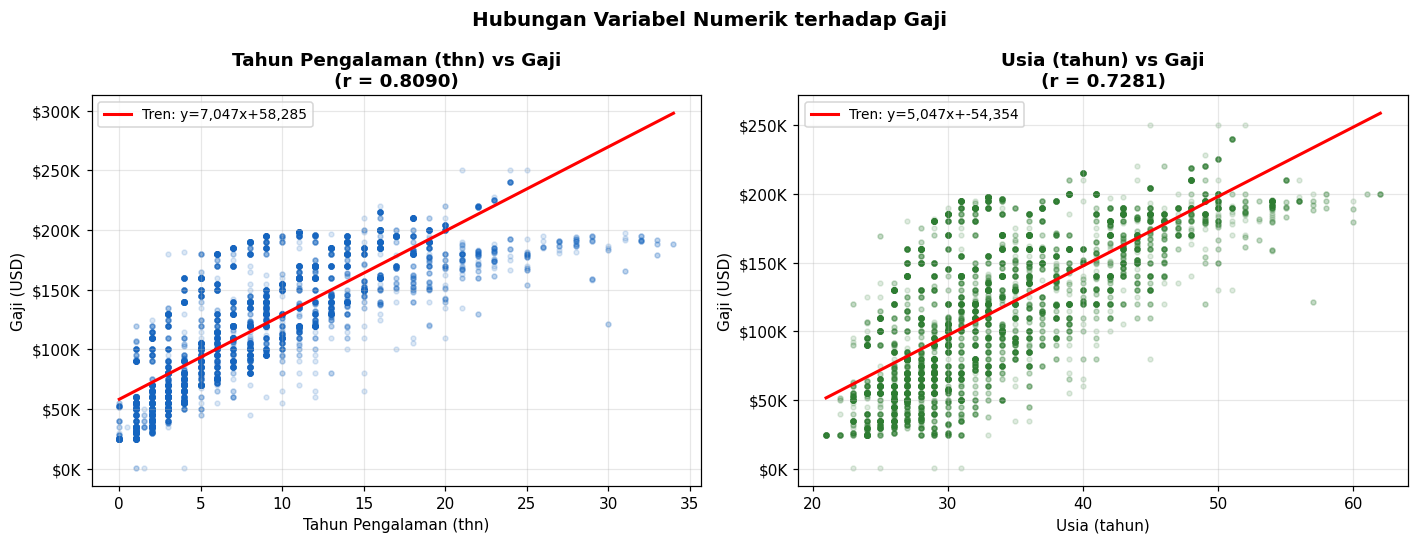

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle("Hubungan Variabel Numerik terhadap Gaji",
             fontsize=13, fontweight="bold")

for i, (var, lbl, clr) in enumerate([
    ("Tahun_Pengalaman", "Tahun Pengalaman (thn)", "#1565C0"),
    ("Usia",             "Usia (tahun)",            "#2E7D32"),
]):
    ax = axes[i]
    ax.scatter(df[var], df["Gaji"], alpha=0.15, color=clr, s=10)
    m, b_lin = np.polyfit(df[var], df["Gaji"], 1)
    xl = np.linspace(df[var].min(), df[var].max(), 200)
    ax.plot(xl, m * xl + b_lin, "r-", linewidth=2,
            label=f"Tren: y={m:,.0f}x+{b_lin:,.0f}")
    r = df[var].corr(df["Gaji"])
    ax.set_title(f"{lbl} vs Gaji\n(r = {r:.4f})", fontweight="bold")
    ax.set_xlabel(lbl)
    ax.set_ylabel("Gaji (USD)")
    ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"${x/1000:.0f}K"))
    ax.legend(fontsize=9)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

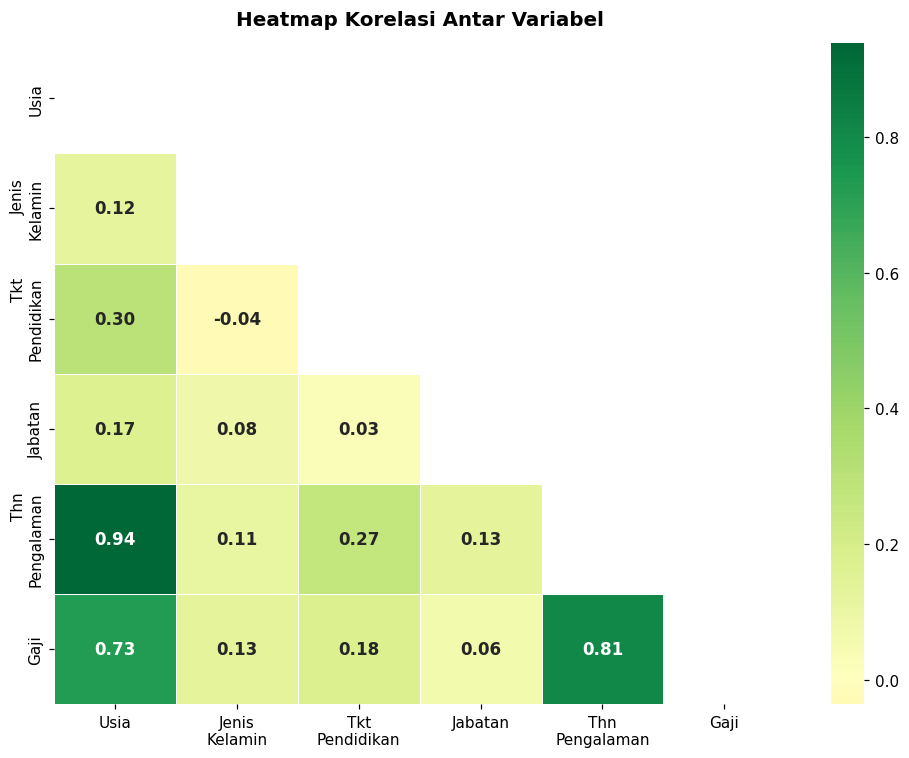


Korelasi setiap variabel independen terhadap Gaji (Y):
  Thn Pengalaman      : r = +0.8090  ->  Sangat Kuat, Positif
  Usia                : r = +0.7281  ->  Kuat, Positif
  Tkt Pendidikan      : r = +0.1767  ->  Sangat Lemah, Positif
  Jenis Kelamin       : r = +0.1273  ->  Sangat Lemah, Positif
  Jabatan             : r = +0.0647  ->  Sangat Lemah, Positif


In [17]:
df_num = df[["Usia", "Jenis_Kelamin_Enc", "Tingkat_Pendidikan_Enc",
             "Jabatan_Enc", "Tahun_Pengalaman", "Gaji"]].copy()
df_num.columns = ["Usia", "Jenis\nKelamin", "Tkt\nPendidikan",
                  "Jabatan", "Thn\nPengalaman", "Gaji"]

fig, ax = plt.subplots(figsize=(9, 7))
mask    = np.triu(np.ones_like(df_num.corr(), dtype=bool))
sns.heatmap(df_num.corr(), annot=True, fmt=".2f", cmap="RdYlGn",
            center=0, mask=mask, ax=ax, linewidths=0.5,
            annot_kws={"size": 11, "weight": "bold"})
ax.set_title("Heatmap Korelasi Antar Variabel",
             fontsize=13, fontweight="bold", pad=12)
plt.tight_layout()
plt.show()

print("")
print("Korelasi setiap variabel independen terhadap Gaji (Y):")
kor_y = df_num.corr()["Gaji"].drop("Gaji").sort_values(ascending=False)
for var, val in kor_y.items():
    kuat = ("Sangat Kuat" if abs(val) >= .8 else
            "Kuat"        if abs(val) >= .6 else
            "Sedang"      if abs(val) >= .4 else
            "Lemah"       if abs(val) >= .2 else "Sangat Lemah")
    arah = "Positif" if val > 0 else "Negatif"
    print(f"  {var.replace(chr(10), ' '):<20}: r = {val:+.4f}  ->  {kuat}, {arah}")

---
## Bagian 6 — Penentuan Variabel dan Pembagian Data

- **Variabel Independen (X): Usia, Jenis Kelamin, Tingkat Pendidikan, Jabatan, Tahun Pengalaman
- Variabel Dependen (Y): Gaji
- Rasio pembagian: 80% Training — 20% Testing

In [18]:
X_COLS = ["Usia", "Jenis_Kelamin_Enc", "Tingkat_Pendidikan_Enc",
          "Jabatan_Enc", "Tahun_Pengalaman"]
Y_COL  = "Gaji"

X = df[X_COLS]
y = df[Y_COL]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("=" * 50)
print("  PEMBAGIAN DATA TRAINING DAN TESTING")
print("=" * 50)
print(f"  Total data    : {len(df):,} baris")
print(f"  Data Training : {len(X_train):,} baris ({len(X_train)/len(df)*100:.0f}%)")
print(f"  Data Testing  : {len(X_test):,} baris  ({len(X_test)/len(df)*100:.0f}%)")
print(f"")
print(f"  Variabel X    : {X_COLS}")
print(f"  Variabel Y    : {Y_COL}")
print("")
print("Data siap untuk pemodelan.")

  PEMBAGIAN DATA TRAINING DAN TESTING
  Total data    : 6,698 baris
  Data Training : 5,358 baris (80%)
  Data Testing  : 1,340 baris  (20%)

  Variabel X    : ['Usia', 'Jenis_Kelamin_Enc', 'Tingkat_Pendidikan_Enc', 'Jabatan_Enc', 'Tahun_Pengalaman']
  Variabel Y    : Gaji

Data siap untuk pemodelan.


---
## Bagian 7 — Pembangunan Model Regresi Linier Berganda

Persamaan umum model regresi linier berganda:

    Y_pred = b0 + b1*X1 + b2*X2 + b3*X3 + b4*X4 + b5*X5

Keterangan variabel:
    Y_pred  =  Gaji prediksi (variabel dependen)
    X1      =  Usia
    X2      =  Jenis Kelamin
    X3      =  Tingkat Pendidikan
    X4      =  Jabatan
    X5      =  Tahun Pengalaman

Model diestimasi menggunakan metode Ordinary Least Squares (OLS).

In [19]:
regressor = LinearRegression()
regressor.fit(X_train, y_train)
print("Model berhasil dilatih.")

print(f"")
print(f"  Intercept (b0) : ${regressor.intercept_:>12,.2f}")
print(f"")
print(f"  Koefisien Regresi:")
print(f"  {'Variabel':<30} {'Koefisien':>12}")
print("  " + "-" * 44)
for name, coef in zip(X_COLS, regressor.coef_):
    print(f"  {name:<30} {coef:>12,.4f}")

Model berhasil dilatih.

  Intercept (b0) : $   98,160.49

  Koefisien Regresi:
  Variabel                          Koefisien
  --------------------------------------------
  Usia                            -1,596.0720
  Jenis_Kelamin_Enc                4,312.2545
  Tingkat_Pendidikan_Enc          -2,028.9019
  Jabatan_Enc                        -30.1701
  Tahun_Pengalaman                 9,049.3491


In [20]:
b0             = regressor.intercept_
b1, b2, b3, b4, b5 = regressor.coef_

print("=" * 60)
print("  PERSAMAAN MODEL REGRESI LINIER BERGANDA")
print("=" * 60)
print(f"  Y (Gaji) = {b0:,.2f}")
print(f"             + ({b1:,.4f}) x Usia")
print(f"             + ({b2:,.4f}) x Jenis_Kelamin_Enc")
print(f"             + ({b3:,.4f}) x Tingkat_Pendidikan_Enc")
print(f"             + ({b4:,.4f}) x Jabatan_Enc")
print(f"             + ({b5:,.4f}) x Tahun_Pengalaman")
print("=" * 60)

  PERSAMAAN MODEL REGRESI LINIER BERGANDA
  Y (Gaji) = 98,160.49
             + (-1,596.0720) x Usia
             + (4,312.2545) x Jenis_Kelamin_Enc
             + (-2,028.9019) x Tingkat_Pendidikan_Enc
             + (-30.1701) x Jabatan_Enc
             + (9,049.3491) x Tahun_Pengalaman


In [21]:
X_train_sm = sm.add_constant(X_train)
ols_model  = sm.OLS(y_train, X_train_sm).fit()
print(ols_model.summary())

                            OLS Regression Results                            
Dep. Variable:                   Gaji   R-squared:                       0.666
Model:                            OLS   Adj. R-squared:                  0.665
Method:                 Least Squares   F-statistic:                     2131.
Date:                Sun, 17 May 2026   Prob (F-statistic):               0.00
Time:                        11:01:21   Log-Likelihood:                -62915.
No. Observations:                5358   AIC:                         1.258e+05
Df Residuals:                    5352   BIC:                         1.259e+05
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
const                   9.81

---
## Bagian 8 — Interpretasi dan Uji Signifikansi

### Uji t (Parsial) — alpha = 0.05
- H0 : bi = 0 (variabel tidak berpengaruh signifikan terhadap Y)
- H1 : bi tidak sama dengan 0 (variabel berpengaruh signifikan terhadap Y)
- Tolak H0 jika p-value < 0.05

### Uji F (Simultan) — alpha = 0.05
- **H0**: Semua koefisien = 0 (model tidak signifikan)
- **H1**: Minimal satu koefisien tidak sama dengan 0 (model signifikan)
- Tolak H0 jika **p-value F < 0.05**

In [22]:
print("=" * 70)
print("  INTERPRETASI KOEFISIEN REGRESI  (dengan asumsi variabel lain tetap)")
print("=" * 70)

interpretasi = [
    ("Konstanta (b0)",
     f"${b0:,.2f}",
     "Nilai dasar gaji ketika semua variabel bernilai 0 (tidak diinterpretasikan secara langsung)."),
    ("Usia (b1)",
     f"${b1:,.2f}",
     f"Setiap penambahan 1 tahun usia, gaji {'naik' if b1 > 0 else 'turun'} sebesar ${abs(b1):,.2f}, "
     f"dengan asumsi variabel lain tetap."),
    ("Jenis Kelamin (b2)",
     f"${b2:,.2f}",
     f"Perbedaan jenis kelamin memengaruhi gaji sebesar ${abs(b2):,.2f} "
     f"(Female=0, Male=1, Other=2)."),
    ("Tingkat Pendidikan (b3)",
     f"${b3:,.2f}",
     f"Setiap kenaikan satu tingkat pendidikan (dalam encoding), gaji berubah ${b3:,.2f}."),
    ("Jabatan (b4)",
     f"${b4:,.2f}",
     f"Setiap kenaikan satu indeks jabatan, gaji berubah ${b4:,.2f} "
     f"(terdapat 193 jabatan unik yang di-encode)."),
    ("Tahun Pengalaman (b5)",
     f"${b5:,.2f}",
     f"Setiap penambahan 1 tahun pengalaman, gaji {'naik' if b5 > 0 else 'turun'} sebesar "
     f"${abs(b5):,.2f}. Ini adalah variabel paling berpengaruh."),
]

for nama, nilai, interp in interpretasi:
    print(f"")
    print(f"  {nama} = {nilai}")
    print(f"     {interp}")

  INTERPRETASI KOEFISIEN REGRESI  (dengan asumsi variabel lain tetap)

  Konstanta (b0) = $98,160.49
     Nilai dasar gaji ketika semua variabel bernilai 0 (tidak diinterpretasikan secara langsung).

  Usia (b1) = $-1,596.07
     Setiap penambahan 1 tahun usia, gaji turun sebesar $1,596.07, dengan asumsi variabel lain tetap.

  Jenis Kelamin (b2) = $4,312.25
     Perbedaan jenis kelamin memengaruhi gaji sebesar $4,312.25 (Female=0, Male=1, Other=2).

  Tingkat Pendidikan (b3) = $-2,028.90
     Setiap kenaikan satu tingkat pendidikan (dalam encoding), gaji berubah $-2,028.90.

  Jabatan (b4) = $-30.17
     Setiap kenaikan satu indeks jabatan, gaji berubah $-30.17 (terdapat 193 jabatan unik yang di-encode).

  Tahun Pengalaman (b5) = $9,049.35
     Setiap penambahan 1 tahun pengalaman, gaji naik sebesar $9,049.35. Ini adalah variabel paling berpengaruh.


In [23]:
print("=" * 72)
print("  UJI t — SIGNIFIKANSI PARSIAL  (alpha = 0.05)")
print("=" * 72)
print(f"  {'Variabel':<30} {'p-value':>10}  {'Keputusan':<22} Hasil")
print("  " + "-" * 70)

pvals = ols_model.pvalues
for col in X_COLS:
    p   = pvals[col]
    kep = "Tolak H0"         if p < 0.05 else "Gagal Tolak H0"
    res = "Signifikan"       if p < 0.05 else "Tidak Signifikan"
    print(f"  {col:<30} {p:>10.4f}  {kep:<22} {res}")

print()
print("=" * 72)
print("  UJI F — SIGNIFIKANSI SIMULTAN  (alpha = 0.05)")
print("=" * 72)
fv  = ols_model.fvalue
fp  = ols_model.f_pvalue
kep = "Tolak H0" if fp < 0.05 else "Gagal Tolak H0"
print(f"  F-statistik : {fv:.4f}")
print(f"  p-value     : {fp:.2e}")
print(f"  Keputusan   : {kep}")
if fp < 0.05:
    print("")
    print("  Model secara keseluruhan SIGNIFIKAN.")
    print("  Minimal satu variabel independen berpengaruh terhadap Gaji.")

  UJI t — SIGNIFIKANSI PARSIAL  (alpha = 0.05)
  Variabel                          p-value  Keputusan              Hasil
  ----------------------------------------------------------------------
  Usia                               0.0000  Tolak H0               Signifikan
  Jenis_Kelamin_Enc                  0.0000  Tolak H0               Signifikan
  Tingkat_Pendidikan_Enc             0.0000  Tolak H0               Signifikan
  Jabatan_Enc                        0.0000  Tolak H0               Signifikan
  Tahun_Pengalaman                   0.0000  Tolak H0               Signifikan

  UJI F — SIGNIFIKANSI SIMULTAN  (alpha = 0.05)
  F-statistik : 2131.0039
  p-value     : 0.00e+00
  Keputusan   : Tolak H0

  Model secara keseluruhan SIGNIFIKAN.
  Minimal satu variabel independen berpengaruh terhadap Gaji.


---
## Bagian 9 — Prediksi Gaji Karyawan

### 9.1 Prediksi Manual
Menggunakan rumus persamaan regresi yang telah diperoleh.

### 9.2 Prediksi Otomatis
Menggunakan method `.predict()` dari scikit-learn pada data testing.

In [24]:
# Prediksi manual berdasarkan rumus regresi
# Contoh: karyawan berusia 35 tahun, laki-laki, pendidikan S2,
#         indeks jabatan 50, pengalaman 8 tahun.
#
# Referensi encoding:
#   Jenis Kelamin      : Female=0, Male=1, Other=2
#   Tingkat Pendidikan : S1=0, S2=1, S3=2, SMA=3
#   Jabatan            : indeks 0 s.d. 192

usia_c       = 35
gender_c     = 1    # Male
pend_c       = 1    # S2
jabatan_c    = 50
pengalaman_c = 8

gaji_manual = (b0
               + b1 * usia_c
               + b2 * gender_c
               + b3 * pend_c
               + b4 * jabatan_c
               + b5 * pengalaman_c)

print("=" * 55)
print("  PREDIKSI GAJI SECARA MANUAL")
print("=" * 55)
print(f"  Usia              : {usia_c} tahun")
print(f"  Jenis Kelamin Enc : {gender_c}  (Male)")
print(f"  Pendidikan Enc    : {pend_c}  (S2)")
print(f"  Jabatan Enc       : {jabatan_c}")
print(f"  Tahun Pengalaman  : {pengalaman_c} tahun")
print(f"")
print(f"  Hasil Prediksi Gaji = ${gaji_manual:,.2f}")

  PREDIKSI GAJI SECARA MANUAL
  Usia              : 35 tahun
  Jenis Kelamin Enc : 1  (Male)
  Pendidikan Enc    : 1  (S2)
  Jabatan Enc       : 50
  Tahun Pengalaman  : 8 tahun

  Hasil Prediksi Gaji = $115,467.61


In [25]:
y_pred = regressor.predict(X_test)

comp = pd.DataFrame({
    "Gaji Aktual ($)"  : y_test.values[:10],
    "Gaji Prediksi ($)": y_pred[:10].round(2),
    "Selisih ($)"      : (y_test.values[:10] - y_pred[:10]).round(2),
})

print("=== PERBANDINGAN AKTUAL vs PREDIKSI (10 Data Pertama) ===")
comp.index = range(1, 11)
print(comp.to_string())

=== PERBANDINGAN AKTUAL vs PREDIKSI (10 Data Pertama) ===
    Gaji Aktual ($)  Gaji Prediksi ($)  Selisih ($)
1      150,000.0000       124,338.8800  25,661.1200
2       75,969.0000        87,937.7300 -11,968.7300
3      100,000.0000        64,736.0800  35,263.9200
4       60,000.0000        77,812.7000 -17,812.7000
5       80,000.0000        96,183.8100 -16,183.8100
6      190,000.0000       133,895.5900  56,104.4100
7       72,000.0000       103,492.1200 -31,492.1200
8       55,000.0000        85,238.7500 -30,238.7500
9      195,000.0000       139,806.0200  55,193.9800
10     130,000.0000       122,009.0300   7,990.9700


---
## Bagian 10 — Visualisasi Hasil Model

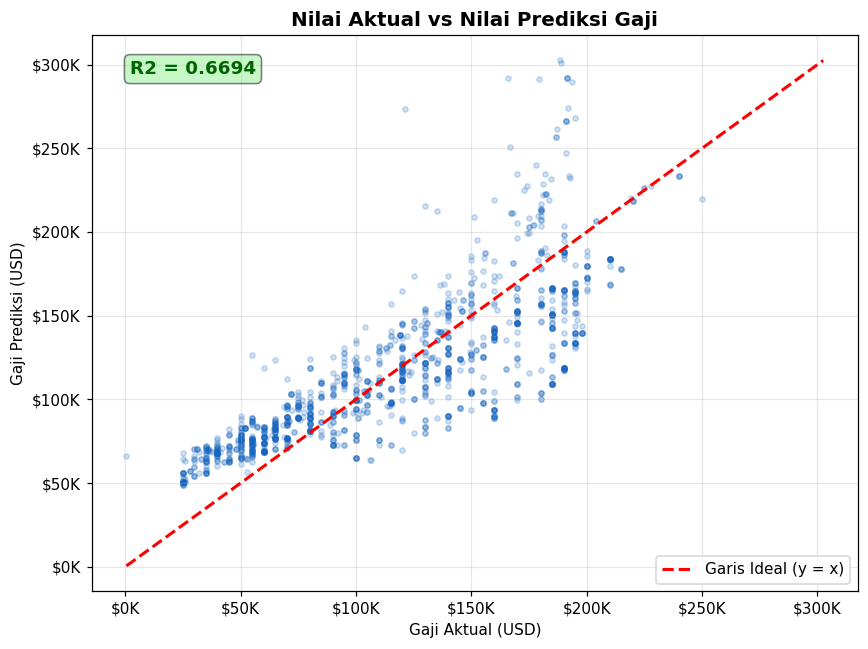

In [26]:
r2_val = r2_score(y_test, y_pred)

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(y_test, y_pred, alpha=0.2, color="#1565C0", s=12)
mn = min(y_test.min(), y_pred.min())
mx = max(y_test.max(), y_pred.max())
ax.plot([mn, mx], [mn, mx], "r--", linewidth=2, label="Garis Ideal (y = x)")
ax.set_title("Nilai Aktual vs Nilai Prediksi Gaji",
             fontsize=13, fontweight="bold")
ax.set_xlabel("Gaji Aktual (USD)")
ax.set_ylabel("Gaji Prediksi (USD)")
fmt = plt.FuncFormatter(lambda x, _: f"${x/1000:.0f}K")
ax.xaxis.set_major_formatter(fmt)
ax.yaxis.set_major_formatter(fmt)
ax.text(0.05, 0.93, f"R2 = {r2_val:.4f}", transform=ax.transAxes,
        fontsize=12, fontweight="bold", color="darkgreen",
        bbox=dict(boxstyle="round", facecolor="lightgreen", alpha=0.5))
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

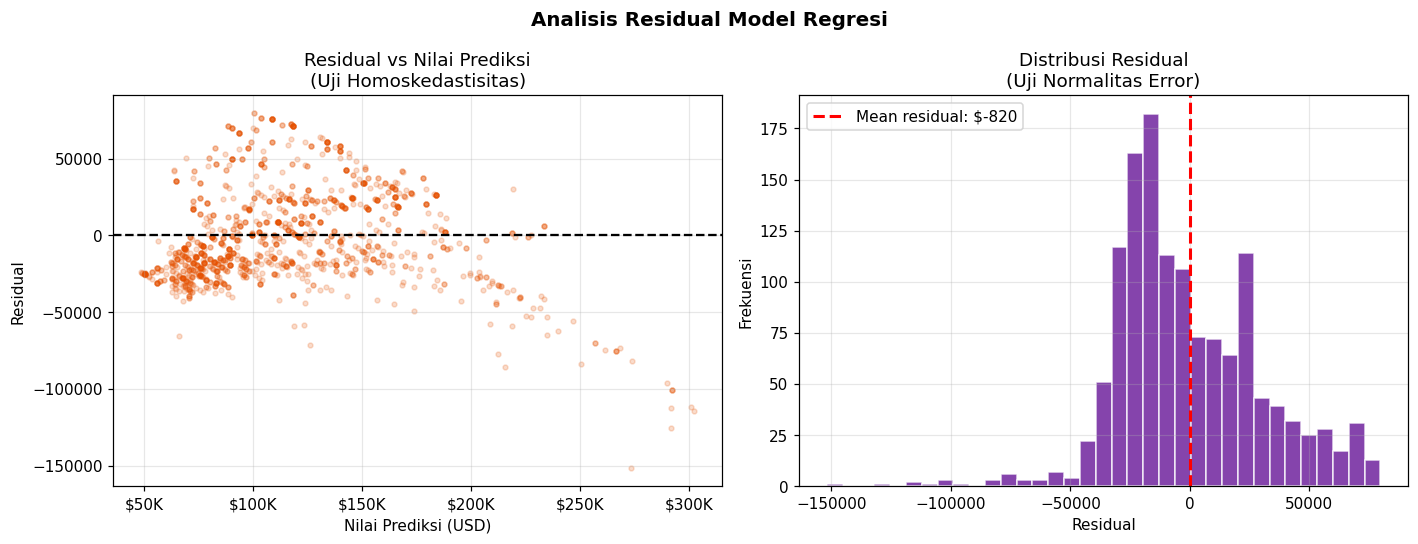

In [27]:
residuals = y_test.values - y_pred

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle("Analisis Residual Model Regresi",
             fontsize=13, fontweight="bold")

axes[0].scatter(y_pred, residuals, alpha=0.2, color="#E65100", s=10)
axes[0].axhline(0, color="black", linewidth=1.5, linestyle="--")
axes[0].set_title("Residual vs Nilai Prediksi\n(Uji Homoskedastisitas)")
axes[0].set_xlabel("Nilai Prediksi (USD)")
axes[0].set_ylabel("Residual")
axes[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"${x/1000:.0f}K"))
axes[0].grid(alpha=0.3)

axes[1].hist(residuals, bins=35, color="#6A1B9A", edgecolor="white", alpha=0.82)
axes[1].axvline(0, color="red", linewidth=2, linestyle="--",
                label=f"Mean residual: ${residuals.mean():,.0f}")
axes[1].set_title("Distribusi Residual\n(Uji Normalitas Error)")
axes[1].set_xlabel("Residual")
axes[1].set_ylabel("Frekuensi")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

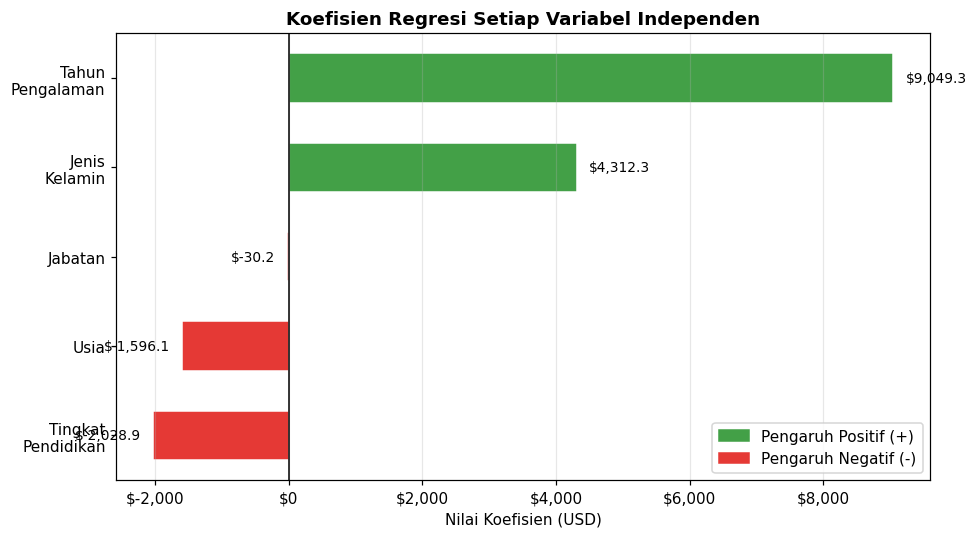

In [28]:
fig, ax = plt.subplots(figsize=(9, 5))

var_labels = ["Usia", "Jenis\nKelamin", "Tingkat\nPendidikan",
              "Jabatan", "Tahun\nPengalaman"]
coefs  = pd.Series(regressor.coef_, index=var_labels).sort_values()
bc     = ["#E53935" if c < 0 else "#43A047" for c in coefs]
bars   = ax.barh(coefs.index, coefs.values, color=bc,
                 edgecolor="white", height=0.55)
ax.axvline(0, color="black", linewidth=1)
ax.set_title("Koefisien Regresi Setiap Variabel Independen",
             fontsize=12, fontweight="bold")
ax.set_xlabel("Nilai Koefisien (USD)")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"${x:,.0f}"))

max_abs = abs(coefs).max()
for bar, val in zip(bars, coefs.values):
    offset = max_abs * 0.02 * (1 if val >= 0 else -1)
    ha     = "left" if val >= 0 else "right"
    ax.text(val + offset, bar.get_y() + bar.get_height() / 2,
            f"${val:,.1f}", va="center", ha=ha, fontsize=9)

pp  = mpatches.Patch(color="#43A047", label="Pengaruh Positif (+)")
np_ = mpatches.Patch(color="#E53935", label="Pengaruh Negatif (-)")
ax.legend(handles=[pp, np_])
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

---
## Bagian 11 — Evaluasi Model

Evaluasi model dilakukan menggunakan metrik berikut:

    R2 (R-squared)   : Proporsi variansi Y yang dapat dijelaskan model.
    Adjusted R2      : R2 yang disesuaikan dengan jumlah variabel prediktor.
    RMSE             : Akar rata-rata kuadrat error, dalam satuan USD.
    MAE              : Rata-rata deviasi absolut antara nilai aktual dan prediksi.

In [29]:
r2    = r2_score(y_test, y_pred)
r2adj = ols_model.rsquared_adj
rmse  = np.sqrt(mean_squared_error(y_test, y_pred))
mae   = mean_absolute_error(y_test, y_pred)
fv    = ols_model.fvalue
fp    = ols_model.f_pvalue

print("=" * 55)
print("       HASIL EVALUASI MODEL")
print("=" * 55)
print(f"  {'R2 Score (Testing)':<32} : {r2:.4f}  ({r2 * 100:.2f}%)")
print(f"  {'Adjusted R2':<32} : {r2adj:.4f}  ({r2adj * 100:.2f}%)")
print(f"  {'RMSE (Root Mean Squared Error)':<32} : ${rmse:>10,.2f}")
print(f"  {'MAE  (Mean Absolute Error)':<32} : ${mae:>10,.2f}")
print(f"  {'F-statistik':<32} : {fv:>10.4f}")
print(f"  {'p-value (F-test)':<32} : {fp:>10.2e}")
print("=" * 55)
print()
print("Interpretasi:")
print(f"  - Model menjelaskan {r2 * 100:.2f}% variasi Gaji karyawan.")
print(f"  - Rata-rata kesalahan prediksi sebesar ${rmse:,.2f}.")
print(f"  - Model {'SIGNIFIKAN' if fp < 0.05 else 'TIDAK SIGNIFIKAN'} "
      f"secara keseluruhan (F-test, p = {fp:.2e}).")
print(f"  - Model {'LAYAK DIGUNAKAN' if r2 >= 0.5 else 'PERLU DITINGKATKAN'} "
      f"(R2 = {r2:.4f}).")

       HASIL EVALUASI MODEL
  R2 Score (Testing)               : 0.6694  (66.94%)
  Adjusted R2                      : 0.6653  (66.53%)
  RMSE (Root Mean Squared Error)   : $ 30,702.38
  MAE  (Mean Absolute Error)       : $ 24,393.34
  F-statistik                      :  2131.0039
  p-value (F-test)                 :   0.00e+00

Interpretasi:
  - Model menjelaskan 66.94% variasi Gaji karyawan.
  - Rata-rata kesalahan prediksi sebesar $30,702.38.
  - Model SIGNIFIKAN secara keseluruhan (F-test, p = 0.00e+00).
  - Model LAYAK DIGUNAKAN (R2 = 0.6694).


---
## Bagian 12 — Kesimpulan

In [30]:
r2    = r2_score(y_test, y_pred)
r2adj = ols_model.rsquared_adj
rmse  = np.sqrt(mean_squared_error(y_test, y_pred))
mae   = mean_absolute_error(y_test, y_pred)
fv    = ols_model.fvalue
fp    = ols_model.f_pvalue
r_pengalaman = df["Tahun_Pengalaman"].corr(df["Gaji"])

print("=" * 65)
print("  KESIMPULAN ANALISIS REGRESI LINIER BERGANDA")
print("=" * 65)

print("")
print("1. PERSAMAAN MODEL:")
print(f"   Y (Gaji) = {b0:,.2f}")
print(f"              + ({b1:,.4f}) x Usia")
print(f"              + ({b2:,.4f}) x Jenis_Kelamin_Enc")
print(f"              + ({b3:,.4f}) x Tingkat_Pendidikan_Enc")
print(f"              + ({b4:,.4f}) x Jabatan_Enc")
print(f"              + ({b5:,.4f}) x Tahun_Pengalaman")

print("")
print("2. KUALITAS MODEL:")
print(f"   R2 Testing  : {r2 * 100:.2f}%")
print(f"   Adj. R2     : {r2adj * 100:.2f}%")
print(f"   RMSE        : ${rmse:,.2f}")
print(f"   MAE         : ${mae:,.2f}")

print("")
print("3. SIGNIFIKANSI VARIABEL (alpha = 0.05):")
pvals = ols_model.pvalues
for col in X_COLS:
    p   = pvals[col]
    sts = "Signifikan" if p < 0.05 else "Tidak Signifikan"
    print(f"   {col:<32}: p = {p:.4f}  ->  {sts}")

print("")
print("4. UJI F SIMULTAN:")
print(f"   F = {fv:.4f} | p = {fp:.2e}  ->  Model SIGNIFIKAN secara keseluruhan.")

print("")
print("5. VARIABEL PALING BERPENGARUH:")
print( "   -> Tahun Pengalaman memiliki kontribusi terbesar terhadap Gaji.")
print(f"      Korelasi r = {r_pengalaman:.4f}, koefisien ${b5:,.2f} per tahun pengalaman.")

print("")
print("6. KESIMPULAN AKHIR:")
print( "   Model regresi linier berganda berhasil dibangun dan terbukti signifikan.")
print( "   Semakin lama pengalaman kerja karyawan, maka semakin besar gajinya.")
print( "   Tahun Pengalaman dan Jabatan adalah faktor utama penentu besarnya gaji.")
print()
print("=" * 65)

  KESIMPULAN ANALISIS REGRESI LINIER BERGANDA

1. PERSAMAAN MODEL:
   Y (Gaji) = 98,160.49
              + (-1,596.0720) x Usia
              + (4,312.2545) x Jenis_Kelamin_Enc
              + (-2,028.9019) x Tingkat_Pendidikan_Enc
              + (-30.1701) x Jabatan_Enc
              + (9,049.3491) x Tahun_Pengalaman

2. KUALITAS MODEL:
   R2 Testing  : 66.94%
   Adj. R2     : 66.53%
   RMSE        : $30,702.38
   MAE         : $24,393.34

3. SIGNIFIKANSI VARIABEL (alpha = 0.05):
   Usia                            : p = 0.0000  ->  Signifikan
   Jenis_Kelamin_Enc               : p = 0.0000  ->  Signifikan
   Tingkat_Pendidikan_Enc          : p = 0.0000  ->  Signifikan
   Jabatan_Enc                     : p = 0.0000  ->  Signifikan
   Tahun_Pengalaman                : p = 0.0000  ->  Signifikan

4. UJI F SIMULTAN:
   F = 2131.0039 | p = 0.00e+00  ->  Model SIGNIFIKAN secara keseluruhan.

5. VARIABEL PALING BERPENGARUH:
   -> Tahun Pengalaman memiliki kontribusi terbesar terhadap Gaji.